<a href="https://colab.research.google.com/github/zgander/flyrank_ml/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zgander/flyrank_ml/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

**Research question:** Can February 2026 observable search/engagement signals rank eligible pages for human review of potential content-refresh opportunities, using March 2026 zero measured GSC clicks as a proxy outcome?

**Decision supported:** order a review queue for editors/SEO analysts. The model does not determine whether a page needs refreshing and cannot show that a refresh will cause recovery. Unit of analysis is a pseudonymized content page. A false positive costs review time; a false negative can leave a page unreviewed.

In [1]:
# Reproducible framing summary
import pandas as pd
question = pd.DataFrame([{
    "Decision": "Prioritize pages for human refresh review",
    "Unit": "Pseudonymized content page",
    "Feature window": "February 2026",
    "Outcome window": "March 2026",
    "Target": "Zero measured GSC clicks with >=1 measured March GSC day",
    "Intended use": "Decision support; not an automatic refresh recommendation"
}])
display(question)


,Decision,Unit,Feature window,Outcome window,Target,Intended use
0,Prioritize pages for human refresh review,Pseudonymized content page,February 2026,March 2026,Zero measured GSC clicks with >=1 measured Mar...,Decision support; not an automatic refresh rec...


## 2. Data

Source: FlyRank ML Internship warehouse, `fact_content_daily_performance`; February 2026 features, March 2026 outcome. Eligible population: 46,152 rows across 31 clients with at least 500 February GSC impressions and measured GSC data in both months; eligible positive rate 15.50%.

Features: `feb_impressions`, `feb_clicks`, `feb_ctr`, `feb_avg_position`, `feb_gsc_available_days`, `feb_ga4_sessions`, `feb_ga4_available_days`. Exclude client/content IDs from predictors; use client ID only for grouped split. Exclude March fields, target-derived trends, product scores/action flags, and identifiers. Coverage selection conditions the evaluation on measured March data.

In [2]:
# Data contract summary (aggregate metadata only; no page-level records)
data_summary = pd.DataFrame([
    {"Item": "Eligible rows", "Value": "46,152"},
    {"Item": "Eligible clients", "Value": "31"},
    {"Item": "Eligible positive rate", "Value": "15.50%"},
    {"Item": "Eligibility floor", "Value": ">= 500 February GSC impressions"},
    {"Item": "Coverage requirement", "Value": "Measured GSC in February and March"},
    {"Item": "Feature set", "Value": "feb_impressions, feb_clicks, feb_ctr, feb_avg_position, feb_gsc_available_days, feb_ga4_sessions, feb_ga4_available_days"},
    {"Item": "Excluded", "Value": "IDs as features; March predictors; target/trend/product-derived fields"}
])
display(data_summary)


,Item,Value
0,Eligible rows,"46,152"
1,Eligible clients,31
2,Eligible positive rate,15.50%
3,Eligibility floor,>= 500 February GSC impressions
4,Coverage requirement,Measured GSC in February and March
5,Feature set,"feb_impressions, feb_clicks, feb_ctr, feb_avg_..."
6,Excluded,IDs as features; March predictors; target/tren...


## 3. Methodology

Target: `went_dark = 1` when a page has at least one measured March GSC day and zero measured GSC clicks in March. Random Forest ranks pages by predicted probability. Primary validation is `GroupShuffleSplit(test_size=0.20, random_state=42)`; random-row split is diagnostic only. Metrics: Precision@50, Average Precision, ROC-AUC, and positive rate. The W04 rule baseline was reconstructed on the W05 held-out cohort. Six leakage checks passed: February-only features, no future/target/product fields, IDs excluded, zero label mismatches, zero client overlap, and all rows meeting the impression floor.

In [3]:
# Methodology and leakage-audit receipt from the executed W06 notebook
method = pd.DataFrame([
    {"Check": "Features computed from February only", "Result": "PASS"},
    {"Check": "No future/target/product fields in features", "Result": "PASS"},
    {"Check": "Client/content IDs excluded from features", "Result": "PASS"},
    {"Check": "Target-label mismatches", "Result": "0"},
    {"Check": "Client overlap in grouped split", "Result": "0"},
    {"Check": "All eligible pages meet 500-impression floor", "Result": "PASS"}
])
display(method)
print("Primary split: GroupShuffleSplit(test_size=0.20, random_state=42). Random-row split is diagnostic only.")


,Check,Result
0,Features computed from February only,PASS
1,No future/target/product fields in features,PASS
2,Client/content IDs excluded from features,PASS
3,Target-label mismatches,0
4,Client overlap in grouped split,0
5,All eligible pages meet 500-impression floor,PASS


Primary split: GroupShuffleSplit(test_size=0.20, random_state=42). Random-row split is diagnostic only.


## 4. Results (vs baseline)

Client-grouped Random Forest: Precision@50 0.760, AP 0.473, ROC-AUC 0.853, test positive rate 15.3%. Random-row diagnostic: Precision@50 0.760, AP 0.478, ROC-AUC 0.857. W04 rule baseline Precision@50 was 0.340 on the W05 held-out cohort (17/50); Random Forest top 50 had 38/50 positives. The +0.420 absolute Precision@50 difference is retrospective enrichment for the defined proxy, not proof of refresh impact. See `../capstone_report.md` and `../../docs/index.html` for the full paper.

In [4]:
# Results copied from executed W05/W06 notebook outputs. Re-run W05/W06 to refresh these values.
results = pd.DataFrame([
    {"Method": "Random-row split (diagnostic)", "Precision@50": 0.760, "Average Precision": 0.478, "ROC-AUC": 0.857, "Test positive rate": "~15.3%"},
    {"Method": "Client-grouped split (primary)", "Precision@50": 0.760, "Average Precision": 0.473, "ROC-AUC": 0.853, "Test positive rate": "15.3%"},
    {"Method": "W04 rule baseline (W05 held-out cohort)", "Precision@50": 0.340, "Average Precision": None, "ROC-AUC": None, "Test positive rate": "15.25% in W05 test"}
])
display(results)
print("Top-50 positives: Random Forest 38/50; W04 baseline 17/50. Absolute Precision@50 difference: +0.420.")


,Method,Precision@50,Average Precision,ROC-AUC,Test positive rate
0,Random-row split (diagnostic),0.76,0.478,0.857,~15.3%
1,Client-grouped split (primary),0.76,0.473,0.853,15.3%
2,W04 rule baseline (W05 held-out cohort),0.34,NaN,NaN,15.25% in W05 test


Top-50 positives: Random Forest 38/50; W04 baseline 17/50. Absolute Precision@50 difference: +0.420.


## 5. Limitations

The label means zero measured clicks in one month, not content decay or a proven refresh opportunity. Eligibility requires >=500 February impressions and measured GSC coverage in both months. Only one feature month and one outcome month are evaluated; the grouped test contains 7 clients. GA4 coverage is sparse. Retrospective model metrics do not establish that a refresh causes recovery; prospective or causal evaluation is needed.

In [5]:
# Limitations checklist
limitations = pd.DataFrame([
    {"Limitation": "Outcome is zero measured clicks, not verified content decay", "Implication": "Use as a review proxy only"},
    {"Limitation": "Eligibility requires >=500 February impressions and measured coverage in both months", "Implication": "Results are conditional on selection and coverage"},
    {"Limitation": "One feature month and one outcome month", "Implication": "Seasonality and longer trends not assessed"},
    {"Limitation": "31 eligible clients; 7 clients in W05 grouped test", "Implication": "Client-level generalization evidence is limited"},
    {"Limitation": "Retrospective evaluation", "Implication": "Cannot claim a refresh causes recovery"}
])
display(limitations)


,Limitation,Implication
0,"Outcome is zero measured clicks, not verified ...",Use as a review proxy only
1,Eligibility requires >=500 February impression...,Results are conditional on selection and coverage
2,One feature month and one outcome month,Seasonality and longer trends not assessed
3,31 eligible clients; 7 clients in W05 grouped ...,Client-level generalization evidence is limited
4,Retrospective evaluation,Cannot claim a refresh causes recovery


## 6. Ranked recommendations

1. Use the rank as a human review aid, not an automatic refresh instruction.
2. Review high-visibility pages first while treating the 500-impression floor as a workflow choice.
3. Display February clicks, impressions, CTR, position, and coverage alongside each score.
4. Route pages with missing measurement coverage to data-quality checks.
5. Track decisions and outcomes prospectively; use a credible comparison group where feasible.
6. Repeat validation across later time windows and more clients before broad use.

In [6]:
# Ranked action playbook
recommendations = pd.DataFrame([
    {"Rank": 1, "Action": "Use model rank to prioritize human review, never auto-refresh", "Why": "High top-50 enrichment for the proxy; no causal evidence"},
    {"Rank": 2, "Action": "Verify technical health, intent match, and content accuracy", "Why": "Zero clicks may have multiple causes"},
    {"Rank": 3, "Action": "Show February metrics and measurement coverage beside each rank", "Why": "Makes the evidence interpretable to reviewers"},
    {"Rank": 4, "Action": "Route missing-coverage pages to measurement checks", "Why": "Avoids treating missing data as a performance signal"},
    {"Rank": 5, "Action": "Track decisions and outcomes prospectively", "Why": "Needed to evaluate workflow utility and potential causal impact"},
    {"Rank": 6, "Action": "Repeat validation on later windows and more clients", "Why": "Tests stability over time and across client groups"}
])
display(recommendations)


,Rank,Action,Why
0,1,"Use model rank to prioritize human review, nev...",High top-50 enrichment for the proxy; no causa...
1,2,"Verify technical health, intent match, and con...",Zero clicks may have multiple causes
2,3,Show February metrics and measurement coverage...,Makes the evidence interpretable to reviewers
3,4,Route missing-coverage pages to measurement ch...,Avoids treating missing data as a performance ...
4,5,Track decisions and outcomes prospectively,Needed to evaluate workflow utility and potent...
5,6,Repeat validation on later windows and more cl...,Tests stability over time and across client gr...


## 7. Artifacts the paper embeds

The deployed paper is `docs/index.html`; it contains the headline metrics, comparison chart, validation table, methodology, limitations, recommendations, and data credit. The markdown report is `work/capstone_report.md`; headline metric receipt is `work/outputs/capstone_metrics.json`. After pushing, enable GitHub Pages from `main` / `/docs` and verify the live URL in an incognito window.

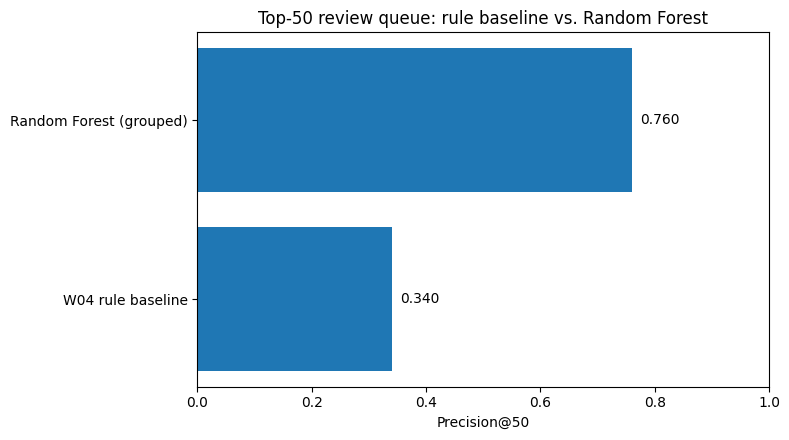

Caption: 38/50 pages in the grouped Random Forest top-50 met the March zero-click target, compared with 17/50 for the W04 rule baseline. This is retrospective ranking enrichment, not causal impact.


In [7]:
# Create the comparison chart locally. This uses aggregate metrics only.
import matplotlib.pyplot as plt
labels = ["W04 rule baseline", "Random Forest (grouped)"]
values = [0.340, 0.760]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(labels, values)
ax.set_xlim(0, 1)
ax.set_xlabel("Precision@50")
ax.set_title("Top-50 review queue: rule baseline vs. Random Forest")
for i, v in enumerate(values):
    ax.text(v + 0.015, i, f"{v:.3f}", va="center")
fig.tight_layout()
plt.show()
print("Caption: 38/50 pages in the grouped Random Forest top-50 met the March zero-click target, compared with 17/50 for the W04 rule baseline. This is retrospective ranking enrichment, not causal impact.")


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [x] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [x] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
